# UCS420 Lab Assignment 7 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160086          # <-- your full roll number
NAME = "Rohin Dudeja"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160086   Name: Rohin Dudeja   Fingerprint: 13DB3153   Tickets: 13

Ticket_ID                                                                                  Ticket_Text
      T01                                                  The state-of-the-art lab (Lab-3) is closed.
      T02                                           The Wi-Fi has stopped syncing. Can you check this?
      T03                         VPN has stopped syncing after restarting the system. This is urgent.
      T04                 MATLAB crashes while opening when connected to campus Wi-Fi. This is urgent.
      T05                                                        The Wi-Fi works, but the VPN doesn't.
      T06                                   The MATLAB stopped responding. I have tried several times!
      T07 I was locked out of the password after resetting my password. The same problem occurs again.
      T08                                                        I need Windows 11 by 5.30 p

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Q1: Preprocessing pipeline

processed = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []

for i, result in enumerate(processed):
    rows.append({
        "Ticket_ID": df.iloc[i]["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

result_table = pd.DataFrame(rows)

# Add TOTAL row for all count-based columns
total = {"Ticket_ID": "TOTAL"}
for col in result_table.columns:
    if col != "Ticket_ID":
        total[col] = result_table[col].sum()

result_table = pd.concat(
    [result_table, pd.DataFrame([total])],
    ignore_index=True
)

display(result_table)

# Display the actual token lists for one focus ticket
focus_id = FOCUS[0]
ticket_index = df.index[df["Ticket_ID"] == focus_id][0]
details = processed[ticket_index]

print("\nSelected Ticket ID:", focus_id)
print("Raw text:", df.loc[ticket_index, "Ticket_Text"])
print("Actual tokens:", details["tokens"])
print("Punctuation tokens:", details["punct"])
print("Stopwords:", details["stops"])
print("Final tokens:", details["final"])


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,1,9,3,2,9,4
1,T02,2,11,2,5,11,4
2,T03,2,13,2,5,12,6
3,T04,2,14,2,5,13,7
4,T05,1,10,2,4,9,4
5,T06,2,11,2,3,11,6
6,T07,2,18,2,10,15,6
7,T08,1,9,1,2,9,6
8,T09,2,14,2,5,12,7
9,T10,2,14,2,6,13,6



Selected Ticket ID: T04
Raw text: MATLAB crashes while opening when connected to campus Wi-Fi. This is urgent.
Actual tokens: ['matlab', 'crashes', 'while', 'opening', 'when', 'connected', 'to', 'campus', 'wi-fi', '.', 'this', 'is', 'urgent', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['while', 'when', 'to', 'this', 'is']
Final tokens: ['matlab', 'crashes', 'opening', 'connected', 'campus', 'wi-fi', 'urgent']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In the selected ticket T04, the final tokens are matlab, crashes, opening, connected, campus, wi-fi, and urgent. These are meaningful words, so no obvious non-word tokens appear in this ticket's final tokens. In other tickets, tokens such as n't, 's, and ca may appear because contractions are split during tokenization.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

# Q2: Regular expression extraction and replacement
import re

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![\w.])(?:0[xX][0-9A-Fa-f]+|\d+(?:\.\d+)+|\d+)(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

# Run extraction on every ticket
for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print(f"\n{row['Ticket_ID']}: {text}")
    for label, pattern in patterns.items():
        print(label, ":", re.findall(pattern, text))

# Run extraction on TEST_LINES too
print("\n--TEST_LINES EXTRACTION--")
for i, text in enumerate(TEST_LINES, start=1):
    print(f"\nTest line {i}: {text}")
    for label, pattern in patterns.items():
        print(label, ":", re.findall(pattern, text))


# Replacement patterns
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"\b(?:https?://|www\.)[^\s<>\"']+"

phone_pattern = (
    r"(?<!\w)"
    r"(?:\+\d{1,3}[-.\s]+)?"
    r"(?:\(\d{2,4}\)[-.\s]*|\d{3}[-.\s-]*)"
    r"\d{3}[-.\s-]*\d{4}"
    r"(?!\w)"
)

def redact_text(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\n--REDACTED TEST_LINES--")
for text in TEST_LINES:
    print("Original:", text)
    print("Redacted:", redact_text(text))

print("\n--REDACTED TICKETS--")
for _, row in df.iterrows():
    print(row["Ticket_ID"], ":", redact_text(row["Ticket_Text"]))



T01: The state-of-the-art lab (Lab-3) is closed.
Words longer than 5 letters : ['closed']
Numbers : ['3']
Capitalized words : ['The', 'Lab']
Words starting with a vowel : ['of', 'art', 'is']

T02: The Wi-Fi has stopped syncing. Can you check this?
Words longer than 5 letters : ['stopped', 'syncing']
Numbers : []
Capitalized words : ['The', 'Wi', 'Fi', 'Can']
Words starting with a vowel : []

T03: VPN has stopped syncing after restarting the system. This is urgent.
Words longer than 5 letters : ['stopped', 'syncing', 'restarting', 'system', 'urgent']
Numbers : []
Capitalized words : ['VPN', 'This']
Words starting with a vowel : ['after', 'is', 'urgent']

T04: MATLAB crashes while opening when connected to campus Wi-Fi. This is urgent.
Words longer than 5 letters : ['MATLAB', 'crashes', 'opening', 'connected', 'campus', 'urgent']
Numbers : []
Capitalized words : ['MATLAB', 'Wi', 'Fi', 'This']
Words starting with a vowel : ['opening', 'is', 'urgent']

T05: The Wi-Fi works, but the VPN do

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 7 words (The,Can,This,It,Please,Write,Can).

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:

from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r"https?://[^\s<>\"']+|"
    r"www\.[^\s<>\"']+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"\+?\d{1,3}[-.\s]?\d{5}[-.\s]?\d{5}|"
    r"\d{4}-\d{3}-\d{4}|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:['’][A-Za-z]+)+|"
    r"[A-Za-z]+(?:-[A-Za-z]+)+|"
    r"[A-Za-z]+|"
    r"\d+|"
    r"[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print("Text:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print()

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    custom = my_tokenize(text)
    standard = word_tokenize(text)
    print(row["Ticket_ID"], "Different:", custom != standard)

different_count = sum(
    my_tokenize(text) != word_tokenize(text)
    for text in df["Ticket_Text"]
)

print("Tickets tokenized differently:", different_count)


Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_toke

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 5 tickets are tokenized differently by my_tokenize() and word_tokenize()

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [7]:
# Your code

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

unique_final = sorted(set(
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
))

words = [word for word in unique_final if word.isalpha()]
tagged_words = pos_tag(words)

suffix_counts = {
    suffix: [word for word in words if word.endswith(suffix)]
    for suffix in ["ing", "ed", "ly", "ies", "es", "s"]
}

valid_suffixes = [
    suffix for suffix, matches in suffix_counts.items()
    if len(matches) >= 2
]

if not valid_suffixes:
    raise ValueError("No candidate suffix occurs in at least two dataset words.")

suffix = max(valid_suffixes, key=lambda s: len(suffix_counts[s]))
regexp_stemmer = RegexpStemmer(suffix, min=3)

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

rows = []

for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    if len({porter_result, lancaster_result, regexp_result, lemma_result}) > 1:
        rows.append({
            "Word": word,
            "POS": tag,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "WordNet Lemma": lemma_result
        })

print("Chosen suffix:", suffix)
print("Words supporting suffix:", suffix_counts[suffix])

stem_table = pd.DataFrame(rows)
display(stem_table)


Chosen suffix: ing
Words supporting suffix: ['opening', 'resetting', 'responding', 'restarting', 'running', 'showing', 'syncing', 'working']


,Word,POS,Porter,Lancaster,Regexp,WordNet Lemma
0,another,DT,anoth,anoth,another,another
1,campus,NN,campu,camp,campus,campus
2,changed,VBD,chang,chang,changed,change
3,closed,VBD,close,clos,closed,close
4,computer,NN,comput,comput,computer,computer
5,connected,VBN,connect,connect,connected,connect
6,crashes,NNS,crash,crash,crashes,crash
7,error,RB,error,er,error,error
8,failed,VBD,fail,fail,failed,fail
9,locked,VBN,lock,lock,locked,lock


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*   
*   Over-stemming: error becomes er with Lancaster Stemmer,removing too much of the original word.
*   Under-stemming: resetting remains resetting with the Regexp Stemmer instead of reducing to reset, because the selected suffix ing is removed only when it matches the end of the word and the minimum-length condition is satisfied.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1: All tokens,153,91,0.594771
1,S2: No punctuation,127,84,0.661417
2,S3: Final tokens,70,57,0.814286
3,S4: Porter stemmed,70,55,0.785714


Top 10 words in S1:


,Word,Frequency
0,.,19
1,the,11
2,is,5
3,this,4
4,i,4
5,wi-fi,3
6,stopped,3
7,to,3
8,password,3
9,has,2


Top 10 words in S3:


,Word,Frequency
0,wi-fi,3
1,stopped,3
2,password,3
3,syncing,2
4,check,2
5,vpn,2
6,urgent,2
7,matlab,2
8,works,2
9,n't,2


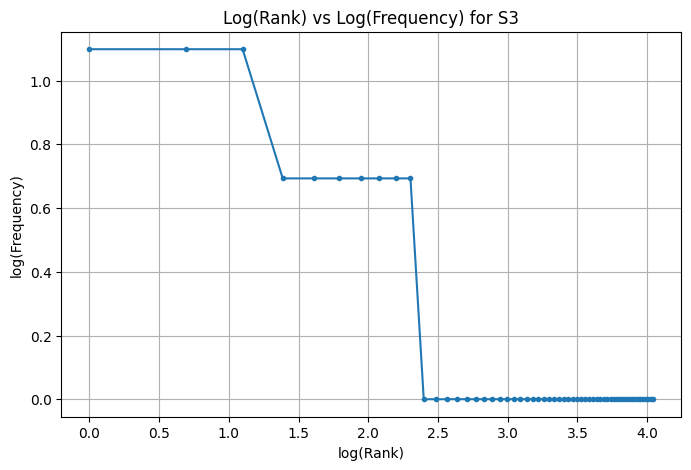

Top 5 bigrams in S1:


,Bigram,Frequency
0,"(., the)",7
1,"(., i)",3
2,"(the, wi-fi)",2
3,"(has, stopped)",2
4,"(stopped, syncing)",2


Top 5 bigrams in S3:


,Bigram,Frequency
0,"(stopped, syncing)",2
1,"(state-of-the-art, lab)",1
2,"(lab, lab-3)",1
3,"(lab-3, closed)",1
4,"(closed, wi-fi)",1


In [9]:
# Your code

from collections import Counter
from nltk.util import bigrams
import math
import matplotlib.pyplot as plt

processed = [process_ticket(text) for text in df["Ticket_Text"]]

S1 = [token for result in processed for token in result["tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in processed for token in result["final"]]

porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]

def corpus_stats(name, tokens):
    return {
        "Corpus": name,
        "Total Tokens": len(tokens),
        "Unique Tokens": len(set(tokens)),
        "TTR": len(set(tokens)) / len(tokens) if tokens else 0
    }

stats = pd.DataFrame([
    corpus_stats("S1: All tokens", S1),
    corpus_stats("S2: No punctuation", S2),
    corpus_stats("S3: Final tokens", S3),
    corpus_stats("S4: Porter stemmed", S4)
])

display(stats)

print("Top 10 words in S1:")
display(pd.DataFrame(Counter(S1).most_common(10),
                     columns=["Word", "Frequency"]))

print("Top 10 words in S3:")
display(pd.DataFrame(Counter(S3).most_common(10),
                     columns=["Word", "Frequency"]))

freq = Counter(S3).most_common()
ranks = range(1, len(freq) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(count) for word, count in freq],
    marker="."
)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

print("Top 5 bigrams in S1:")
display(pd.DataFrame(Counter(bigrams(S1)).most_common(5),
                     columns=["Bigram", "Frequency"]))

print("Top 5 bigrams in S3:")
display(pd.DataFrame(Counter(bigrams(S3)).most_common(5),
                     columns=["Bigram", "Frequency"]))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because token filtering and stemming change the number of unique tokens relative to the total number of tokens. From S1 to S3, removing punctuation and stopwords reduces the total tokens and increases TTR. From S3 to S4, Porter stemming combines related words into common stems, reducing unique tokens from 57 to 55 while the total remains 70. Therefore, TTR decreases slightly from 0.814 to 0.786.